# KAN on the phosphine ligation-state cliff

**Source.** Newman-Stonebraker, Smith, Borowski, Peters, Gensch, Johnson, Sigman, Doyle,
*Science* **2021**, *374*, 301-308 (DOI 10.1126/science.abj4213). Data from the Doyle lab
`ochem-data` repository (`Vbur/rxns/smiles.csv`); ligand descriptors from the *kraken* library
(Gensch et al., *JACS* **2022**, *144*, 1205), file `kraken/kraken.csv`.

**Reaction.** Ni(COD)$_2$-catalyzed Suzuki-Miyaura coupling of aryl chlorides with aryl boronic
acids (K$_3$PO$_4$, dioxane/water, 60 °C), run with 90 monodentate phosphines under five
substrate pairs: 450 reactions.

**The paper's finding.** Yield against most steric descriptors is a cloud. Against the minimum
percent buried volume over the ligand's conformer ensemble, $\%V_\mathrm{bur}(\min)$, it is a
cliff: ligands below about 32 % form the active bis-ligated L$_2$Ni species and can couple;
ligands above it form L$_1$Ni and give no product whatever their other properties. The
threshold was confirmed by NMR ligation-state studies and by DFT dissociation energies.

**Descriptors used here.** Twelve kraken descriptors covering sterics ($\%V_\mathrm{bur}$ min,
Boltzmann and max; Sterimol B1, B5, L), electronics (HOMO, LUMO, V$_\min$, P NBO charge),
geometry (pyramidalization) and polarity (dipole), plus indicators for the five substrate pairs.
kraken stores buried volumes in Å$^3$ inside the 3.5 Å sphere; dividing by the sphere volume
(179.6 Å$^3$) gives the percent values the paper uses (PPh$_3$ 28.2 %, P(*t*-Bu)$_3$ 36.3 %).

**Target.** Active (1) when the yield is at least 10 %, the band the paper shades as inactive in
its Figure 2, otherwise 0. This is a classification notebook; the KAN is fit to the 0/1 label and
read as a probability.

## What this notebook does

Every dataset notebook in this series runs the same pipeline from `pycse.sklearn.kan_interpret`,
so the results are comparable across chemistries:

1. **Models on identical folds.** A linear baseline, random forest, gradient boosting and a KAN
   scored by 5x3 repeated cross-validation with the scaler refit inside each fold, and a paired
   Wilcoxon test of the KAN against the best other model.
2. **Single-descriptor thresholds.** Class-balanced stumps scored by balanced accuracy, with the
   majority baseline, so a "rule" that only predicts the majority class scores 0.5.
3. **Partial effects with fold envelopes.** One-descriptor response curves of the KAN in the
   descriptor's own units, with the linear baseline on the same grid and the envelope of five
   refits. A shape that changes from fold to fold is not a finding.
4. **A check against the known chemistry.** What the source paper established, or (for the
   synthetic benchmark) the generating equations, overlaid on what the pipeline recovered.

No emoji, no claims from a single fit.


In [1]:
import os

os.environ["JAX_PLATFORM_NAME"] = "cpu"
import time
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    RandomForestClassifier,
    GradientBoostingClassifier,
)
from sklearn.metrics import r2_score, mean_absolute_error, roc_auc_score, accuracy_score

from pycse.sklearn.kan import KAN
from pycse.sklearn.kan_interpret import (
    classify_shape,
    cv_compare,
    partial_effects,
    partial_effects_cv,
    plot_fold_scores,
    plot_partial_effect,
    sensitivity,
    threshold_rules,
)
from pycse.sklearn._plotstyle import (
    INK_2,
    MUTED,
    GRID,
    BASELINE,
    SURFACE,
    SERIES,
    PX,
    style_axes,
    finish_axes,
)

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

# Record the environment: KAN fits move slightly between jax/XLA builds.
import importlib.metadata as _md

print(
    "Versions:",
    ", ".join(
        f"{p} {_md.version(p)}" for p in ("pycse", "jax", "optax", "numpy", "scikit-learn", "scipy")
    ),
)


Versions: pycse 2.13.0, jax 0.12.0.1, optax 0.2.8, numpy 2.5.4, scikit-learn 1.9.1, scipy 1.18.1


## 1. Load the reactions and join the kraken descriptors

Ligands are matched to kraken by name (two CataCXium entries carry a trade-name prefix) with a
canonical-SMILES fallback. kraken has several rows for some ligands (conformer sets); the first is
kept.


In [2]:
from rdkit import Chem, RDLogger

RDLogger.DisableLog("rdApp.*")  # the kraken table has blank SMILES rows

BASE = "https://raw.githubusercontent.com/doyle-lab-ucla/ochem-data/main/"
rxn = pd.read_csv(BASE + "Vbur/rxns/smiles.csv")
kraken = pd.read_csv(BASE + "kraken/kraken.csv")
SPHERE = 4.0 / 3.0 * np.pi * 3.5**3  # 179.6 cubic angstrom


def canon(s):
    m = Chem.MolFromSmiles(str(s))
    return Chem.MolToSmiles(m) if m is not None else None


kraken["key"] = kraken["ligand"].astype(str).str.lower().str.strip()
kraken["csmi"] = kraken["can_smiles"].where(kraken["can_smiles"].notna()).map(canon)
kraken = kraken.drop_duplicates("key")
rxn["key"] = rxn["ligand_name"].str.lower().str.strip()
rxn["csmi"] = rxn["ligand_smiles"].map(canon)

by_name = rxn.merge(kraken, on="key", how="left", suffixes=("", "_k"))
missing = by_name["id"].isna()
by_smi = rxn[missing].merge(kraken.drop_duplicates("csmi"), on="csmi", how="left", suffixes=("", "_k"))
data = pd.concat([by_name[~missing], by_smi]).reset_index(drop=True)
print(f"{len(rxn)} reactions; matched by name {(~missing).sum()}, by SMILES {by_smi['id'].notna().sum()}, unmatched {data['id'].isna().sum()}")
data = data[data["id"].notna()].copy()

KRAKEN = {
    "pct_Vbur_min": ("vbur_vbur_min", 100.0 / SPHERE),
    "pct_Vbur_Boltz": ("vbur_vbur_boltz", 100.0 / SPHERE),
    "pct_Vbur_max": ("vbur_vbur_max", 100.0 / SPHERE),
    "Sterimol_B1": ("sterimol_B1_boltz", 1.0),
    "Sterimol_B5": ("sterimol_B5_boltz", 1.0),
    "Sterimol_L": ("sterimol_L_boltz", 1.0),
    "E_HOMO": ("fmo_e_homo_boltz", 1.0),
    "E_LUMO": ("fmo_e_lumo_boltz", 1.0),
    "V_min": ("vmin_vmin_boltz", 1.0),
    "NBO_charge_P": ("nbo_P_boltz", 1.0),
    "pyramidalization_P": ("pyr_P_boltz", 1.0),
    "dipole": ("dipolemoment_boltz", 1.0),
}
X_df = pd.DataFrame({k: data[c].astype(float) * s for k, (c, s) in KRAKEN.items()})

# the five substrate pairs, by SMILES
ELEC = {"ClC1=CC=C(C(F)(F)F)C=C1": "4-CF3-C6H4Cl", "ClC1=CC=C(OC)C=C1": "4-MeO-C6H4Cl"}
NUC = {
    "OB(O)C1=CC=C(C(F)(F)F)C=C1": "4-CF3-phenyl", "OB(O)C1=C(C)C=C(C)C=C1C": "mesityl",
    "OB(O)C1=CC=C(C(OCC)=O)C=C1": "4-CO2Et-phenyl", "OB(O)C1=CC=C(OC)C=C1": "4-MeO-phenyl",
    "OB(O)C1=CC=CC=C1": "phenyl",
}  # fmt: skip
data["reaction"] = data.chloride_smiles.map(ELEC) + " + " + data.boronic_acid_smiles.map(NUC) + "B(OH)2"
assert data["reaction"].notna().all() and data["reaction"].nunique() == 5
REACTIONS = sorted(data["reaction"].unique())
for r in REACTIONS[1:]:  # the first pair is the reference level
    X_df["rxn: " + r] = (data["reaction"] == r).astype(float)
X_df.index = data.index

# Active, relative to the reaction. The five pairs differ in intrinsic reactivity: the best
# ligand reaches 91 % with one pair and 25 % with another, so one pooled yield cut would call
# most ligands active in the easy pair and almost none in the hard one. The paper shades an
# inactive band per reaction; here a ligand counts as active when it reaches a quarter of the
# best yield obtained with that same substrate pair.
best = data.groupby("reaction")["yield"].transform("max")
ACTIVE_FRACTION = 0.25
y = (data["yield"] >= ACTIVE_FRACTION * best).astype(int).to_numpy()
TASK = "classification"
Y_LABEL = "P(active)"
SUCCESS = y
SUCCESS_RULE = f"yield at least {ACTIVE_FRACTION:.0%} of the best yield with the same substrate pair"
COMPONENT = {k: "ligand sterics" for k in ["pct_Vbur_min", "pct_Vbur_Boltz", "pct_Vbur_max", "Sterimol_B1", "Sterimol_B5", "Sterimol_L"]}
COMPONENT.update({k: "ligand electronics" for k in ["E_HOMO", "E_LUMO", "V_min", "NBO_charge_P", "pyramidalization_P", "dipole"]})
COMPONENT.update({c: "substrate pair" for c in X_df.columns if c.startswith("rxn:")})
print(data.groupby("reaction").agg(mean_yield=("yield", "mean"), best=("yield", "max"), n=("yield", "size"), active=("yield", lambda s: (s >= ACTIVE_FRACTION * s.max()).mean())).round(2))
display(X_df.describe().T[["mean", "min", "max"]].round(2))


450 reactions; matched by name 450, by SMILES 0, unmatched 0
                                     mean_yield   best   n  active
reaction                                                          
4-CF3-C6H4Cl + 4-MeO-phenylB(OH)2         36.97   91.0  90    0.57
4-MeO-C6H4Cl + 4-CF3-phenylB(OH)2         20.14   90.0  90    0.33
4-MeO-C6H4Cl + 4-CO2Et-phenylB(OH)2        9.56  100.0  90    0.13
4-MeO-C6H4Cl + mesitylB(OH)2               9.73   63.0  90    0.24
4-MeO-C6H4Cl + phenylB(OH)2               15.16  100.0  90    0.23


,mean,min,max
pct_Vbur_min,32.58,21.33,57.18
pct_Vbur_Boltz,38.58,21.33,68.34
pct_Vbur_max,43.52,21.33,82.56
Sterimol_B1,4.43,2.97,6.33
Sterimol_B5,7.44,3.48,12.39
Sterimol_L,8.09,5.72,14.30
E_HOMO,-0.22,-0.27,-0.18
E_LUMO,-0.02,-0.08,0.04
V_min,-0.05,-0.08,-0.01
NBO_charge_P,0.78,0.61,0.88


450 reactions, 16 descriptors. Target: P(active) (classification).
Success for the threshold rules: yield at least 25% of the best yield with the same substrate pair (30% of reactions).


,Component,Distinct,Min,Max
pct_Vbur_min,ligand sterics,90,21.331,57.182
pct_Vbur_Boltz,ligand sterics,90,21.331,68.338
pct_Vbur_max,ligand sterics,90,21.331,82.557
Sterimol_B1,ligand sterics,90,2.970,6.333
Sterimol_B5,ligand sterics,90,3.482,12.389
Sterimol_L,ligand sterics,90,5.719,14.305
E_HOMO,ligand electronics,90,-0.271,-0.182
E_LUMO,ligand electronics,90,-0.080,0.042
V_min,ligand electronics,90,-0.081,-0.013
NBO_charge_P,ligand electronics,90,0.612,0.879


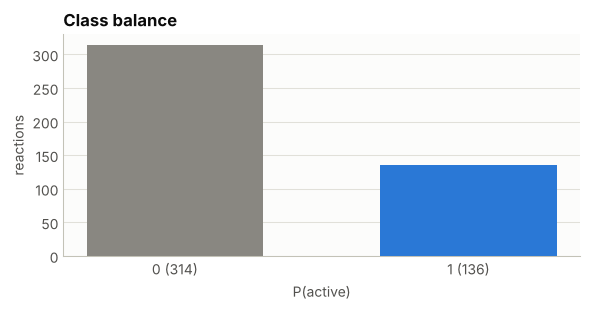

In [3]:
feature_names = list(X_df.columns)
X = X_df.to_numpy(dtype=float)
y = np.asarray(y, dtype=float)
SUCCESS = np.asarray(SUCCESS, dtype=int)
n_features = len(feature_names)
COMPONENTS = list(dict.fromkeys(COMPONENT[f] for f in feature_names))
COMP_COLOR = {c: SERIES[k % len(SERIES)] for k, c in enumerate(COMPONENTS)}

desc = pd.DataFrame(
    {
        "Component": [COMPONENT[f] for f in feature_names],
        "Distinct": X_df.nunique().values,
        "Min": X_df.min().values,
        "Max": X_df.max().values,
    },
    index=feature_names,
)
print(f"{len(X)} reactions, {n_features} descriptors. Target: {Y_LABEL} ({TASK}).")
print(f"Success for the threshold rules: {SUCCESS_RULE} ({SUCCESS.mean():.0%} of reactions).")
display(desc.round(3))

fig, ax = plt.subplots(figsize=(6, 3.2))
style_axes(ax)
if TASK == "regression":
    ax.hist(y, bins=30, color=SERIES[0], edgecolor=SURFACE, linewidth=0.5)
    finish_axes(ax, "Target distribution", Y_LABEL, "reactions")
else:
    vals, counts = np.unique(y, return_counts=True)
    ax.bar(vals, counts, width=0.6, color=[MUTED, SERIES[0]], linewidth=0)
    ax.set_xticks(vals)
    ax.set_xticklabels([f"{int(v)} ({c})" for v, c in zip(vals, counts)])
    finish_axes(ax, "Class balance", Y_LABEL, "reactions")
plt.tight_layout()
plt.show()


## 2. Models on identical folds

The four models see exactly the same 15 folds (5 splits x 3 repeats, scaler refit per fold).
The paired comparison asks a narrow question: on the same held-out reactions, is the KAN better
than the best of the other models, and how often?


Model                  auc              other
Logistic               0.871 ± 0.031   0.813 ± 0.031 (accuracy)
Random Forest          0.886 ± 0.029   0.834 ± 0.039 (accuracy)
Gradient Boosting      0.938 ± 0.015   0.874 ± 0.034 (accuracy)
KAN                    0.845 ± 0.054   0.824 ± 0.045 (accuracy)
KAN vs Gradient Boosting, paired over 15 folds: Δauc = -0.0926 ± 0.0464, KAN better in 0/15, Wilcoxon p = 6.1e-05
(107 s)


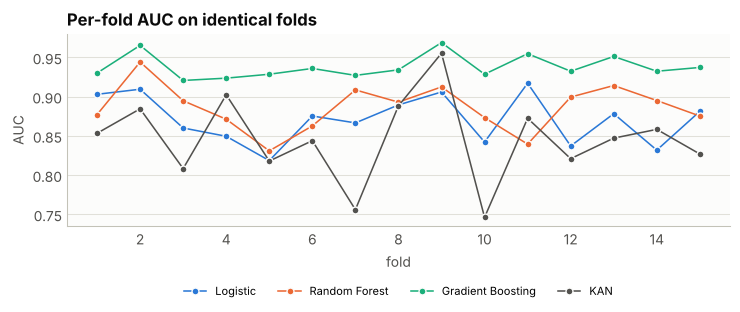

In [4]:
# One hidden layer; width 8 and 5 knots on datasets of 1000 reactions or more,
# 4 and 3 below that, so the spline count stays in proportion to the data.
WIDE = len(X) >= 1000
KAN_LAYERS = (n_features, 8 if WIDE else 4, 1)
KAN_GRID = 5 if WIDE else 3
KAN_MAXITER = 300
CV_SPLITS, CV_REPEATS, CV_SEED = 5, 3, 42


def make_kan():
    return KAN(layers=KAN_LAYERS, grid_size=KAN_GRID, spline_order=3)


def make_models():
    """Fresh models; the ensembles use the settings of the first two chemistry notebooks."""
    if TASK == "regression":
        return {
            "MLR": LinearRegression(),
            "Random Forest": RandomForestRegressor(
                n_estimators=300, max_depth=12, min_samples_split=5, min_samples_leaf=2,
                random_state=42, n_jobs=-1,
            ),  # fmt: skip
            "Gradient Boosting": GradientBoostingRegressor(
                n_estimators=300, learning_rate=0.1, max_depth=4, min_samples_split=5,
                min_samples_leaf=3, subsample=0.8, random_state=42,
            ),  # fmt: skip
            "KAN": make_kan(),
        }
    return {
        "Logistic": LogisticRegression(max_iter=2000),
        "Random Forest": RandomForestClassifier(
            n_estimators=300, max_depth=12, min_samples_split=5, min_samples_leaf=2,
            random_state=42, n_jobs=-1,
        ),  # fmt: skip
        "Gradient Boosting": GradientBoostingClassifier(
            n_estimators=300, learning_rate=0.1, max_depth=4, min_samples_split=5,
            min_samples_leaf=3, subsample=0.8, random_state=42,
        ),  # fmt: skip
        "KAN": make_kan(),
    }


BASELINE_NAME = "MLR" if TASK == "regression" else "Logistic"

t0 = time.time()
cv_result = cv_compare(
    make_models(),
    X,
    y,
    task=TASK,
    n_splits=CV_SPLITS,
    n_repeats=CV_REPEATS,
    random_state=CV_SEED,
    fit_kwargs={"KAN": {"maxiter": KAN_MAXITER}},
    verbose=False,
)
print(cv_result)
print(f"({time.time() - t0:.0f} s)")

fig, ax = plt.subplots(figsize=(7.5, 3.4))
plot_fold_scores(ax, cv_result)
ax.legend(frameon=False, fontsize=8, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.25))
plt.tight_layout()
plt.show()


Held-out split: 360 train / 90 test


,Test AUC,Test accuracy
Model,,
Logistic,0.801,0.778
Random Forest,0.849,0.822
Gradient Boosting,0.898,0.822
KAN,0.773,0.789


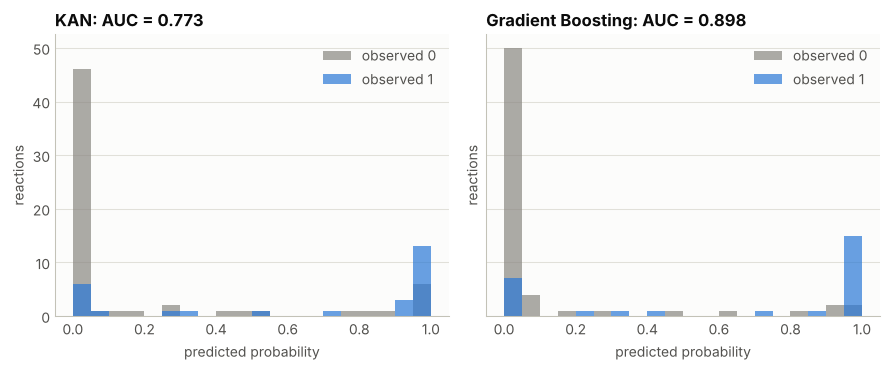

In [5]:
# One held-out split for the models the rest of the notebook interprets.
strat = y.astype(int) if TASK == "classification" else None
idx_tr, idx_te = train_test_split(np.arange(len(X)), test_size=0.2, random_state=42, stratify=strat)
scaler = StandardScaler().fit(X[idx_tr])
X_tr, X_te = scaler.transform(X[idx_tr]), scaler.transform(X[idx_te])
y_tr, y_te = y[idx_tr], y[idx_te]

fitted, rows = {}, []
for name, model in make_models().items():
    if name == "KAN":
        model.fit(X_tr, y_tr, maxiter=KAN_MAXITER)
    else:
        model.fit(X_tr, y_tr.astype(int) if TASK == "classification" else y_tr)
    fitted[name] = model
    if TASK == "regression":
        p = model.predict(X_te)
        rows.append({"Model": name, "Test R2": r2_score(y_te, p), "Test MAE": mean_absolute_error(y_te, p)})
    else:
        p = model.predict_proba(X_te)[:, 1] if hasattr(model, "predict_proba") else np.clip(model.predict(X_te), 0, 1)
        rows.append({"Model": name, "Test AUC": roc_auc_score(y_te, p), "Test accuracy": accuracy_score(y_te, (p > 0.5).astype(int))})
kan, baseline = fitted["KAN"], fitted[BASELINE_NAME]


def model_means(labels, model=None):
    """Observed and predicted mean target per group, over the training reactions.

    A partial effect fixes the other descriptors at their mean, which is not a real
    compound; to compare a model with observed group means, average its predictions
    over the reactions that were actually run.
    """
    model = model or kan
    pred = np.ravel(model.predict(X_tr))
    lab = np.asarray(labels)[idx_tr]
    return (
        pd.DataFrame({"label": lab, "observed": y[idx_tr], "predicted": pred})
        .groupby("label")
        .agg(observed=("observed", "mean"), predicted=("predicted", "mean"), n=("observed", "size"))
    )
headline = pd.DataFrame(rows).set_index("Model")
print(f"Held-out split: {len(idx_tr)} train / {len(idx_te)} test")
display(headline.round(3))

# The KAN against the best other model on the held-out reactions
metric = "Test R2" if TASK == "regression" else "Test AUC"
best_other = headline.drop("KAN")[metric].idxmax()
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), sharex=True, sharey=True)
for ax, name in zip(axes, ["KAN", best_other]):
    style_axes(ax)
    m = fitted[name]
    if TASK == "regression":
        p = m.predict(X_te)
        lim = [min(y_te.min(), p.min()), max(y_te.max(), p.max())]
        ax.plot(lim, lim, color=BASELINE, linewidth=PX, zorder=1)
        ax.scatter(y_te, p, s=12, color=SERIES[0], alpha=0.6, linewidths=0, zorder=2)
        finish_axes(ax, f"{name}: R2 = {headline.loc[name, metric]:.3f}", f"observed {Y_LABEL}", "predicted")
    else:
        p = m.predict_proba(X_te)[:, 1] if hasattr(m, "predict_proba") else np.clip(m.predict(X_te), 0, 1)
        bins = np.linspace(0, 1, 21)
        ax.hist(p[y_te == 0], bins=bins, color=MUTED, alpha=0.7, label="observed 0", linewidth=0)
        ax.hist(p[y_te == 1], bins=bins, color=SERIES[0], alpha=0.7, label="observed 1", linewidth=0)
        ax.legend(frameon=False, fontsize=8)
        finish_axes(ax, f"{name}: AUC = {headline.loc[name, metric]:.3f}", "predicted probability", "reactions")
plt.tight_layout()
plt.show()


## 3. Single-descriptor thresholds

The Doyle and Sigman groups look for reactivity cliffs with one cut on one descriptor. The same
search here: a depth-1 tree with balanced class weights on each descriptor, scored on the held-out
reactions by balanced accuracy. A descriptor with no information scores 0.5 whatever the class
balance.


Majority-class accuracy on the test reactions: 0.700
Balanced-accuracy baseline for guessing: 0.500


,Feature,Threshold,Balanced_Acc,Accuracy,Precision,Recall
0,dipole,2.451,0.696,0.589,0.419,0.963
1,V_min,-0.049,0.667,0.533,0.391,1.000
2,pct_Vbur_min,32.630,0.653,0.544,0.391,0.926
3,E_LUMO,-0.034,0.648,0.522,0.382,0.963
4,E_HOMO,-0.234,0.622,0.500,0.368,0.926
5,Sterimol_B1,4.217,0.614,0.533,0.373,0.815
6,pyramidalization_P,0.888,0.590,0.456,0.347,0.926
7,NBO_charge_P,0.800,0.590,0.456,0.347,0.926
8,Sterimol_B5,8.476,0.587,0.689,0.474,0.333
9,pct_Vbur_max,40.535,0.585,0.567,0.370,0.630


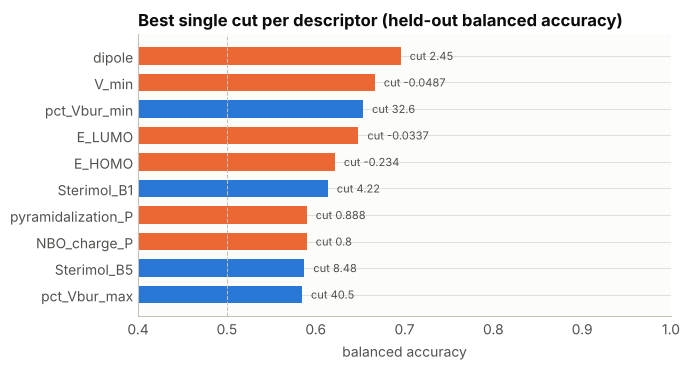

In [6]:
rules = threshold_rules(X[idx_tr], SUCCESS[idx_tr], feature_names, X[idx_te], SUCCESS[idx_te])
print(f"Majority-class accuracy on the test reactions: {rules.attrs['majority_accuracy']:.3f}")
print("Balanced-accuracy baseline for guessing: 0.500")
display(rules.head(10).round(3))

top = rules.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 3.8))
style_axes(ax)
ax.barh(top.Feature, top.Balanced_Acc, color=[COMP_COLOR[COMPONENT[f]] for f in top.Feature], height=0.65, linewidth=0)
ax.axvline(0.5, color=BASELINE, linewidth=PX, linestyle="--")
ax.set_xlim(0.4, 1.0)
for yk, (f, b, t) in enumerate(zip(top.Feature, top.Balanced_Acc, top.Threshold)):
    ax.text(b + 0.01, yk, f"cut {t:.3g}", va="center", fontsize=8, color=INK_2)
finish_axes(ax, "Best single cut per descriptor (held-out balanced accuracy)", "balanced accuracy", "")
plt.tight_layout()
plt.show()


## 4. Partial effects with fold envelopes

Sensitivity ranks the descriptors by how much the KAN prediction moves per standardized unit,
averaged over the training reactions. The top descriptors get a response curve in their own units
(the other descriptors at their mean), the linear baseline on the same grid, and the envelope of
five refits on disjoint folds. The support strip along the bottom shows where the data are.


,Feature,Component,Sensitivity
0,NBO_charge_P,ligand electronics,0.5198
1,pyramidalization_P,ligand electronics,0.4557
2,pct_Vbur_min,ligand sterics,0.3208
3,E_HOMO,ligand electronics,0.2781
4,pct_Vbur_max,ligand sterics,0.2637
5,Sterimol_B5,ligand sterics,0.2633
6,E_LUMO,ligand electronics,0.2584
7,V_min,ligand electronics,0.2566
8,pct_Vbur_Boltz,ligand sterics,0.2548
9,rxn: 4-MeO-C6H4Cl + mesitylB(OH)2,substrate pair,0.2024


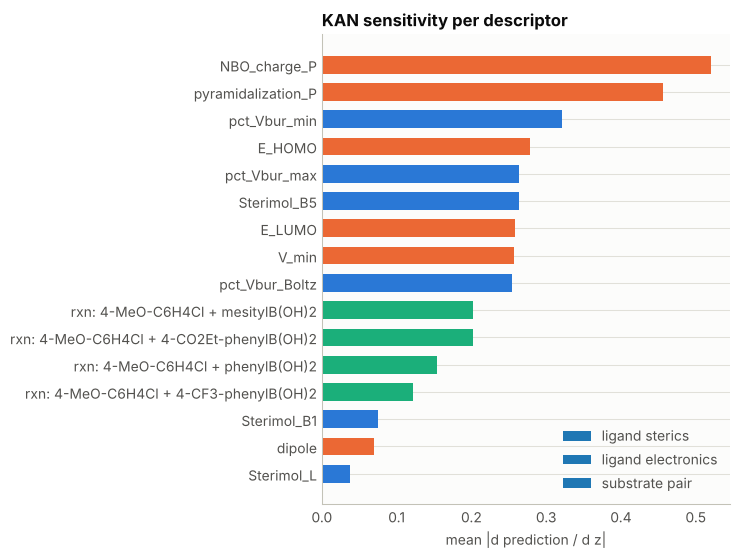

12 descriptors with at least 5 distinct values; 4 with fewer, shown as levels below.


fold envelopes: 27 s


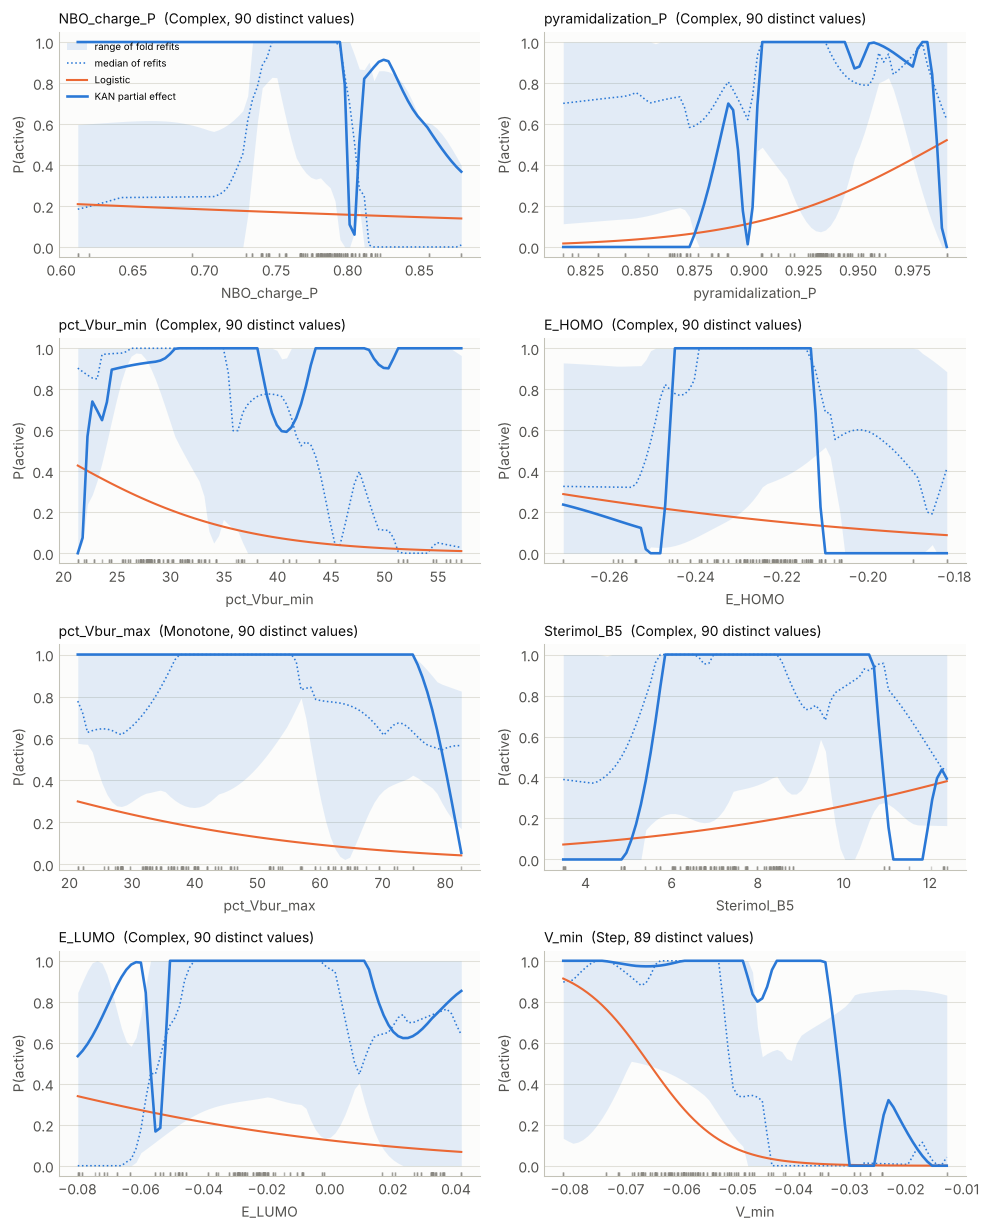

In [7]:
sens = sensitivity(kan, X_tr, task=TASK)
sens_df = pd.DataFrame(
    {"Feature": feature_names, "Component": [COMPONENT[f] for f in feature_names], "Sensitivity": sens}
).sort_values("Sensitivity", ascending=False).reset_index(drop=True)
display(sens_df.round(4))

fig, ax = plt.subplots(figsize=(7.5, 0.28 * n_features + 1.2))
style_axes(ax)
sd = sens_df.iloc[::-1]
ax.barh(sd.Feature, sd.Sensitivity, color=[COMP_COLOR[c] for c in sd.Component], height=0.65, linewidth=0)
for c in COMPONENTS:
    ax.barh([], [], color=COMP_COLOR[c], label=c)
ax.legend(frameon=False, fontsize=8, loc="lower right")
finish_axes(ax, "KAN sensitivity per descriptor", "mean |d prediction / d z|", "")
plt.tight_layout()
plt.show()

# A response curve needs values to interpolate between. Descriptors with fewer
# than five distinct values are handled as levels in the next cell instead.
MIN_LEVELS = 5
rich = [f for f in feature_names if X_df[f].nunique() >= MIN_LEVELS]
few = [f for f in feature_names if f not in rich]
top_features = sens_df[sens_df.Feature.isin(rich)].Feature.head(8).tolist()
TOP_K = len(top_features)
print(f"{len(rich)} descriptors with at least {MIN_LEVELS} distinct values; {len(few)} with fewer, shown as levels below.")
effects = partial_effects(
    kan, X[idx_tr], feature_names, top_features, scaler=scaler, task=TASK,
    extra_models={BASELINE_NAME: baseline},
)  # fmt: skip
t0 = time.time()
effects = partial_effects_cv(
    make_kan, X, y, feature_names, top_features, task=TASK, n_splits=5, random_state=42,
    fit_kwargs={"maxiter": KAN_MAXITER}, effects=effects, verbose=False,
)  # fmt: skip
print(f"fold envelopes: {time.time() - t0:.0f} s")

ncol = 2
nrow = int(np.ceil(TOP_K / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(10, 3.1 * nrow))
for ax, f in zip(np.ravel(axes), top_features):
    plot_partial_effect(ax, effects[f], ylabel=Y_LABEL)
    ax.set_title(f"{f}  ({effects[f].shape(scale=y.std() if TASK == 'regression' else 1.0)[0]}, {effects[f].n_unique} distinct values)", loc="left", fontsize=10)
for ax in np.ravel(axes)[TOP_K:]:
    ax.axis("off")
for ax in np.ravel(axes)[1:TOP_K]:  # one legend is enough
    if ax.get_legend():
        ax.get_legend().remove()
np.ravel(axes)[0].legend(frameon=False, fontsize=7, loc="best")
plt.tight_layout()
plt.show()


In [8]:
# Descriptors with four or fewer levels. A response curve needs a grid; these get a
# table instead: the observed mean per level and the model's mean prediction over the
# same reactions (not at an averaged molecule, which is not a real compound).
if few:
    pred_tr = np.ravel(kan.predict(X_tr))
    rows = []
    for f in few:
        j = feature_names.index(f)
        for lvl in np.unique(X[:, j]):
            at = X[idx_tr, j] == lvl
            rows.append(
                {
                    "Feature": f,
                    "Component": COMPONENT[f],
                    "Level": lvl,
                    "Reactions": int((X[:, j] == lvl).sum()),
                    "Observed mean": float(y[X[:, j] == lvl].mean()),
                    "KAN mean prediction": float(pred_tr[at].mean()) if at.any() else np.nan,
                }
            )
    levels = pd.DataFrame(rows)
    display(levels.round(3))
    spread = levels.groupby("Feature")["Observed mean"].agg(lambda s: s.max() - s.min())
    print("Observed spread across the levels of each few-level descriptor:")
    print(spread.round(1).sort_values(ascending=False).to_string())
else:
    levels = pd.DataFrame()
    print("Every descriptor has at least five distinct values; nothing to show here.")


,Feature,Component,Level,Reactions,Observed mean,KAN mean prediction
0,rxn: 4-MeO-C6H4Cl + 4-CF3-phenylB(OH)2,substrate pair,0.0,360,0.294,0.287
1,rxn: 4-MeO-C6H4Cl + 4-CF3-phenylB(OH)2,substrate pair,1.0,90,0.333,0.366
2,rxn: 4-MeO-C6H4Cl + 4-CO2Et-phenylB(OH)2,substrate pair,0.0,360,0.344,0.348
3,rxn: 4-MeO-C6H4Cl + 4-CO2Et-phenylB(OH)2,substrate pair,1.0,90,0.133,0.113
4,rxn: 4-MeO-C6H4Cl + mesitylB(OH)2,substrate pair,0.0,360,0.317,0.322
5,rxn: 4-MeO-C6H4Cl + mesitylB(OH)2,substrate pair,1.0,90,0.244,0.229
6,rxn: 4-MeO-C6H4Cl + phenylB(OH)2,substrate pair,0.0,360,0.319,0.318
7,rxn: 4-MeO-C6H4Cl + phenylB(OH)2,substrate pair,1.0,90,0.233,0.236


Observed spread across the levels of each few-level descriptor:
Feature
rxn: 4-MeO-C6H4Cl + 4-CO2Et-phenylB(OH)2    0.2
rxn: 4-MeO-C6H4Cl + mesitylB(OH)2           0.1
rxn: 4-MeO-C6H4Cl + phenylB(OH)2            0.1
rxn: 4-MeO-C6H4Cl + 4-CF3-phenylB(OH)2      0.0


In [9]:
# Shape of the single fit, and whether the five refits agree on it. A curve whose
# range is under 5 % of the target's spread is "Constant" whatever its wiggles.
SHAPE_SCALE = y.std() if TASK == "regression" else 1.0


def stability_table(effects):
    rows = []
    for f, pe in effects.items():
        label, note = pe.shape(scale=SHAPE_SCALE)
        fold_labels = [classify_shape(pe.x_std, c, scale=SHAPE_SCALE)[0] for c in pe.curves]
        agree = float(np.mean([lab == label for lab in fold_labels]))
        width = float(np.mean(pe.hi - pe.lo) / (np.ptp(pe.median) + 1e-9))
        rows.append(
            {
                "Feature": f,
                "Component": COMPONENT[f],
                "Shape": label,
                "Nonlinearity": pe.nonlinearity(),
                "Fold agreement": agree,
                "Envelope / range": width,
                "Fold shapes": ", ".join(fold_labels),
            }
        )
    return pd.DataFrame(rows)


stab = stability_table(effects)
display(stab.round(3))
stable = stab[(stab["Fold agreement"] >= 0.8) & (stab["Envelope / range"] < 0.5)]
print("Shapes that survive refitting (4/5 folds agree, refits disagree by less than half the curve range):")
for _, r in stable.iterrows():
    print(f"  {r.Feature}: {r.Shape}")
print("Shapes that do not:")
for _, r in stab.drop(stable.index).iterrows():
    print(f"  {r.Feature}: single fit {r.Shape}; folds {r['Fold shapes']}")


,Feature,Component,Shape,Nonlinearity,Fold agreement,Envelope / range,Fold shapes
0,NBO_charge_P,ligand electronics,Complex,0.744,1.0,0.621,"Complex, Complex, Complex, Complex, Complex"
1,pyramidalization_P,ligand electronics,Complex,0.625,1.0,1.847,"Complex, Complex, Complex, Complex, Complex"
2,pct_Vbur_min,ligand sterics,Complex,0.912,0.4,0.789,"Complex, Complex, Saturating, Step, Step"
3,E_HOMO,ligand electronics,Complex,0.977,0.6,1.063,"Complex, Complex, Step, Complex, Step"
4,pct_Vbur_max,ligand sterics,Monotone,0.869,0.0,1.372,"Complex, Complex, Complex, Inverted U, Complex"
5,Sterimol_B5,ligand sterics,Complex,0.980,0.8,1.282,"Complex, Linear, Complex, Complex, Complex"
6,E_LUMO,ligand electronics,Complex,0.999,0.8,0.811,"Complex, Complex, Complex, Complex, Step"
7,V_min,ligand electronics,Step,0.597,0.6,0.725,"Complex, Step, Step, Complex, Step"


Shapes that survive refitting (4/5 folds agree, refits disagree by less than half the curve range):
Shapes that do not:
  NBO_charge_P: single fit Complex; folds Complex, Complex, Complex, Complex, Complex
  pyramidalization_P: single fit Complex; folds Complex, Complex, Complex, Complex, Complex
  pct_Vbur_min: single fit Complex; folds Complex, Complex, Saturating, Step, Step
  E_HOMO: single fit Complex; folds Complex, Complex, Step, Complex, Step
  pct_Vbur_max: single fit Monotone; folds Complex, Complex, Complex, Inverted U, Complex
  Sterimol_B5: single fit Complex; folds Complex, Linear, Complex, Complex, Complex
  E_LUMO: single fit Complex; folds Complex, Complex, Complex, Complex, Step
  V_min: single fit Step; folds Complex, Step, Step, Complex, Step


## 5. Check against the paper

The paper's Figure 2 (bottom row) is yield against $\%V_\mathrm{bur}(\min)$ per reaction with
the inactive band shaded. The first figure reproduces it from the joined data with the 32 % line.
The table then compares the paper's rule with the cut the stump found and with where the KAN
curve drops.


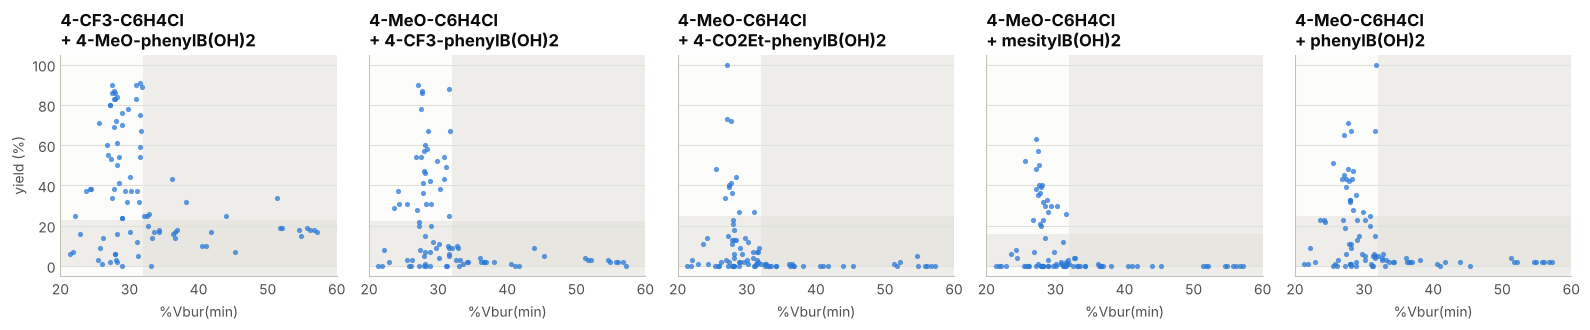

,Rule,Cut (%),Balanced accuracy
0,paper: %Vbur(min) < 32,32.000,0.694
1,stump on %Vbur(min),32.630,0.689
2,KAN curve midpoint,22.239,0.481


The paper's rule, applied to each substrate pair on its own:
  4-CF3-C6H4Cl + 4-MeO-phenylB(OH)2: balanced accuracy 0.713 (n = 90, active 57%)
  4-MeO-C6H4Cl + 4-CF3-phenylB(OH)2: balanced accuracy 0.742 (n = 90, active 33%)
  4-MeO-C6H4Cl + 4-CO2Et-phenylB(OH)2: balanced accuracy 0.686 (n = 90, active 13%)
  4-MeO-C6H4Cl + mesitylB(OH)2: balanced accuracy 0.713 (n = 90, active 24%)
  4-MeO-C6H4Cl + phenylB(OH)2: balanced accuracy 0.710 (n = 90, active 23%)

KAN curve midpoint per fold refit: [48.1, 41.8, 22.7, 46.7, 35.9]
Reactions at or above 32 %: 145, active 7; best yield there 43 %
Active fraction by %Vbur(min) bin:
          mean  count
(20, 26]  0.24     50
(26, 29]  0.52    165
(29, 31]  0.38     40
(31, 32]  0.32     50
(32, 33]  0.15     20
(33, 35]  0.00     25
(35, 40]  0.07     30
(40, 60]  0.03     70


In [10]:
PAPER_CUT = 32.0
fig, axes = plt.subplots(1, len(REACTIONS), figsize=(3.2 * len(REACTIONS), 3.4), sharey=True)
for ax, r in zip(axes, REACTIONS):
    style_axes(ax)
    sub = data[data["reaction"] == r]
    ax.axvspan(PAPER_CUT, 60, color=GRID, alpha=0.5, linewidth=0)
    ax.axhspan(0, ACTIVE_FRACTION * sub["yield"].max(), color=GRID, alpha=0.5, linewidth=0)
    ax.scatter(X_df.loc[sub.index, "pct_Vbur_min"], sub["yield"], s=14, color=SERIES[0], alpha=0.75, linewidths=0, zorder=3)
    ax.set_xlim(20, 60)
    finish_axes(ax, r.replace(" + ", "\n+ "), "%Vbur(min)", "yield (%)" if ax is axes[0] else "")
    ax.title.set_fontsize(8.5)
plt.tight_layout()
plt.show()

v = X_df["pct_Vbur_min"].to_numpy()


def balanced_acc(rule, mask=None):
    m = np.ones(len(y), bool) if mask is None else mask
    return 0.5 * (rule[m & (y == 1)].mean() + (~rule[m & (y == 0)]).mean())


stump_cut = rules.set_index("Feature").loc["pct_Vbur_min", "Threshold"]
pe = effects["pct_Vbur_min"]
mid = 0.5 * (pe.y.max() + pe.y.min())
kan_cross = pe.x_raw[np.argmin(np.abs(pe.y - mid))]
fold_cross = [pe.x_raw[np.argmin(np.abs(c - 0.5 * (c.max() + c.min())))] for c in pe.curves]
cmp = pd.DataFrame(
    [
        {"Rule": "paper: %Vbur(min) < 32", "Cut (%)": PAPER_CUT, "Balanced accuracy": balanced_acc(v < PAPER_CUT)},
        {"Rule": "stump on %Vbur(min)", "Cut (%)": stump_cut, "Balanced accuracy": balanced_acc(v < stump_cut)},
        {"Rule": "KAN curve midpoint", "Cut (%)": kan_cross, "Balanced accuracy": balanced_acc(v < kan_cross)},
    ]
)  # fmt: skip
display(cmp.round(3))
print("The paper's rule, applied to each substrate pair on its own:")
for r in REACTIONS:
    m = (data["reaction"] == r).to_numpy()
    print(f"  {r}: balanced accuracy {balanced_acc(v < PAPER_CUT, m):.3f} (n = {m.sum()}, active {y[m].mean():.0%})")
print("")
print(f"KAN curve midpoint per fold refit: {np.round(fold_cross, 1).tolist()}")
above = data["yield"][v >= PAPER_CUT]
print(f"Reactions at or above 32 %: {len(above)}, active {int(y[v >= PAPER_CUT].sum())}; best yield there {above.max():.0f} %")
print("Active fraction by %Vbur(min) bin:")
print(pd.Series(y).groupby(pd.cut(v, [20, 26, 29, 31, 32, 33, 35, 40, 60]), observed=True).agg(["mean", "count"]).round(2))


### Reading

The paper's rule is reproduced from the data. The KAN does not find it.

**The 32 % rule holds.** A ligand with %Vbur(min) below 32 % reaching a quarter of the best yield
for its substrate pair, and one above it failing, is right at a balanced accuracy of 0.694 over
all 450 reactions, and 0.686 to 0.742 within each of the five substrate pairs separately. The
class-balanced stump, which was given no prior knowledge, cuts at 32.6 %. The active fraction
falls from 0.52 between 26 and 29 % buried volume to 0.15 just above the threshold and 0.03 above
40 %. Of the 145 reactions run with a ligand at or above 32 %, 7 clear the bar and the best yield
anywhere in that region is 43 %.

**The KAN does not place the cliff.** Its %Vbur(min) curve crosses its own midpoint at 22 % in
the full fit, and at 23, 36, 42, 47 and 48 % in the five fold refits. No descriptor's shape
survives both stability tests. The two descriptors on which all five refits agree are labelled
Complex, which is not a reading, and their envelopes are 0.6 and 1.8 times the curve range. Gradient boosting is also the better classifier (cross-validated AUC 0.938
against 0.845, better in 15 folds of 15).

**Why this dataset defeats the flexible model.** 450 reactions carry 90 ligands described by
twelve mutually correlated descriptors, three of which are buried volumes of the same molecule.
A one-parameter rule on a single descriptor is estimable from that; a spline surface over twelve
is not. The known-truth benchmark in this series makes the same step visible with 600 reactions
and five independent descriptors, so the difference is the design of the descriptor set, not the
method.

**What to take from it.** When the chemistry is a threshold in one known descriptor, fit the
threshold. The value of the KAN here is the negative result it reports honestly: the envelope
says the curves are not evidence, and the single cut that is evidence agrees with the paper.


## 6. Summary dashboard

Four tiles, all from the numbers above: cross-validated score per model, the best single cuts,
the sensitivity grouped by reaction component, and the stability of the top response curves.


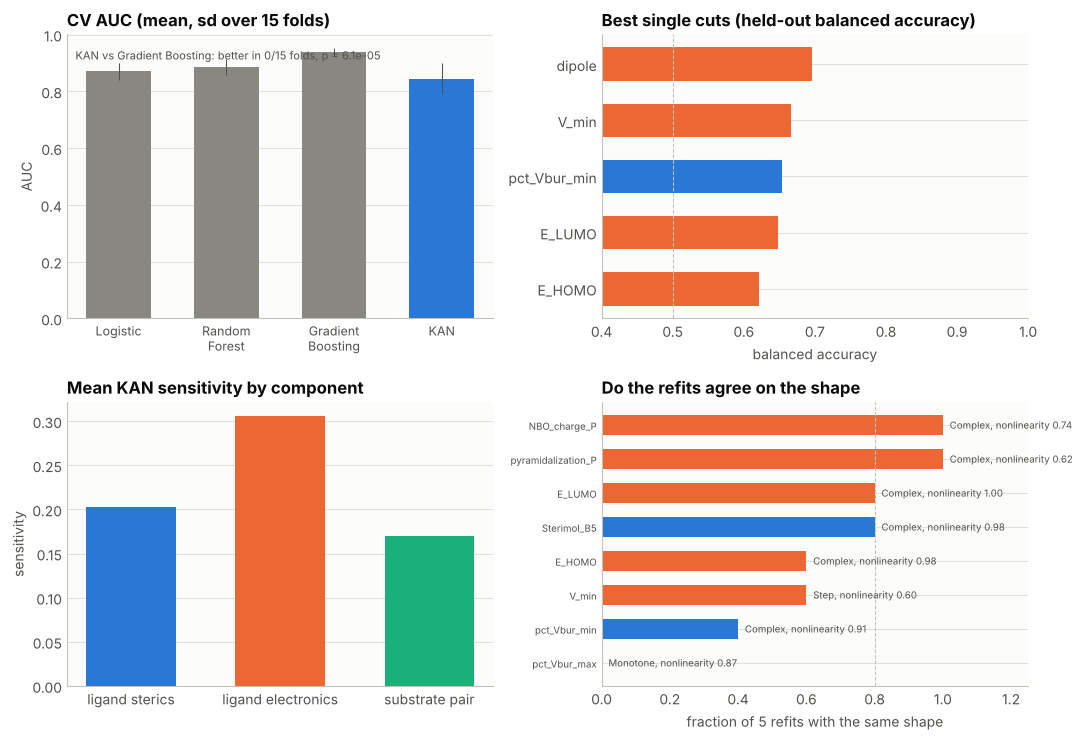

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7.5))
ax = axes[0, 0]
style_axes(ax)
s = cv_result.summary
names = list(s.index)
ax.bar(names, s[cv_result.metric + "_mean"], yerr=s[cv_result.metric + "_std"], color=[MUTED] * (len(names) - 1) + [SERIES[0]], width=0.6, linewidth=0, error_kw={"elinewidth": PX, "ecolor": INK_2})
ax.set_xticks(range(len(names)))
ax.set_xticklabels([n.replace(" ", "\n") for n in names], fontsize=9)
p = cv_result.pairwise
finish_axes(ax, f"CV {cv_result.metric.upper()} (mean, sd over {CV_SPLITS * CV_REPEATS} folds)", "", cv_result.metric.upper())
ax.text(0.02, 0.95, f"KAN vs {p['vs']}: better in {p['wins']}/{p['n']} folds, p = {p['p']:.2g}", transform=ax.transAxes, va="top", fontsize=8, color=INK_2)

ax = axes[0, 1]
style_axes(ax)
top5 = rules.head(5).iloc[::-1]
ax.barh(top5.Feature, top5.Balanced_Acc, color=[COMP_COLOR[COMPONENT[f]] for f in top5.Feature], height=0.6, linewidth=0)
ax.axvline(0.5, color=BASELINE, linewidth=PX, linestyle="--")
ax.set_xlim(0.4, 1.0)
finish_axes(ax, "Best single cuts (held-out balanced accuracy)", "balanced accuracy", "")

ax = axes[1, 0]
style_axes(ax)
comp_sens = sens_df.groupby("Component")["Sensitivity"].mean().reindex(COMPONENTS)
ax.bar(comp_sens.index, comp_sens.values, color=[COMP_COLOR[c] for c in comp_sens.index], width=0.6, linewidth=0)
finish_axes(ax, "Mean KAN sensitivity by component", "", "sensitivity")

ax = axes[1, 1]
style_axes(ax)
st = stab.sort_values(["Fold agreement", "Nonlinearity"])
ax.barh(st.Feature, st["Fold agreement"], color=[COMP_COLOR[c] for c in st.Component], height=0.6, linewidth=0)
ax.axvline(0.8, color=BASELINE, linewidth=PX, linestyle="--")
ax.set_xlim(0, 1.25)
for yk, (a, nl, sh) in enumerate(zip(st["Fold agreement"], st["Nonlinearity"], st.Shape)):
    ax.text(a + 0.02, yk, f"{sh}, nonlinearity {nl:.2f}", va="center", fontsize=7, color=INK_2)
ax.tick_params(axis="y", labelsize=7)
finish_axes(ax, "Do the refits agree on the shape", "fraction of 5 refits with the same shape", "")
plt.tight_layout()
plt.show()
